In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid
import pandas as pd
import cmcrameri.cm as cm
from matplotlib.patches import Rectangle
from matplotlib.patches import Polygon
from scipy.io import savemat
import h5py


import analysis_functions as afn

In [2]:
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-nr.tif') as img:
    streak_pre_nr = np.array(img)
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-r.tif') as img:
    streak_pre_r = np.array(img)   
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak.tif') as img:
    streak = np.array(img)   

calib = pd.read_csv('streak_calib.csv')

In [3]:
px_to_mm = calib['value'].values[0]
px_to_ns = calib['value'].values[1]
print(px_to_ns*3)

calib_factors = [px_to_ns, px_to_mm]

cmax = np.percentile(streak, 99)

0.1004481480808545


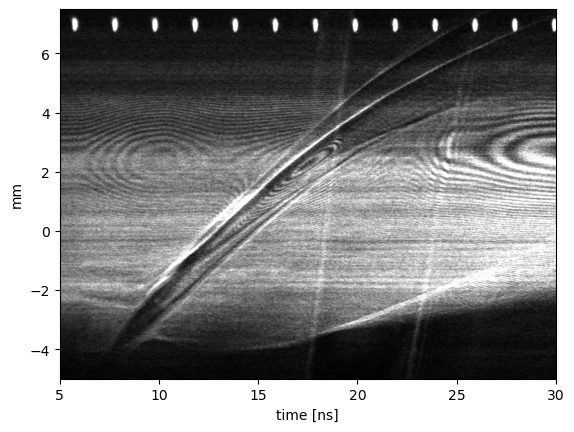

In [4]:
fig, ax = plt.subplots()

extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.xlim(5, 30)
# plt.xlim(18, 24)
plt.ylim(-5,7.5)

plt.savefig('streak_images/zfs/streak_zoom.jpg', bbox_inches = 'tight')

In [5]:
times_bkgd = np.linspace(3, 5, 51)
times_bkgd = np.array(times_bkgd)
pos_bkgd, lineouts_bkgd = afn.get_lineouts(streak, times_bkgd, bg = np.array([0,0]), cf = calib_factors, ext = ext)

mask = (times_bkgd > 4.0) | (times_bkgd < 3.5)
times_bkgd = times_bkgd[mask]
pos_bkgd = pos_bkgd[mask]
lineouts_bkgd = lineouts_bkgd[mask]

In [6]:
background = np.mean(lineouts_bkgd, axis = 0)

In [7]:
times_shock = np.linspace(10, 30, 21)
pos_shock, lineouts_shock = afn.get_lineouts(streak, times_shock, background, calib_factors, ext)

background subtracting...


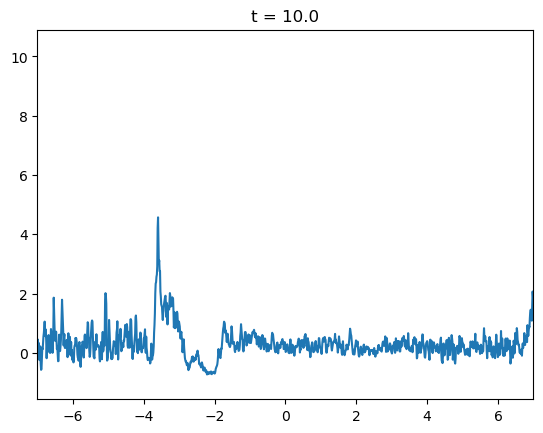

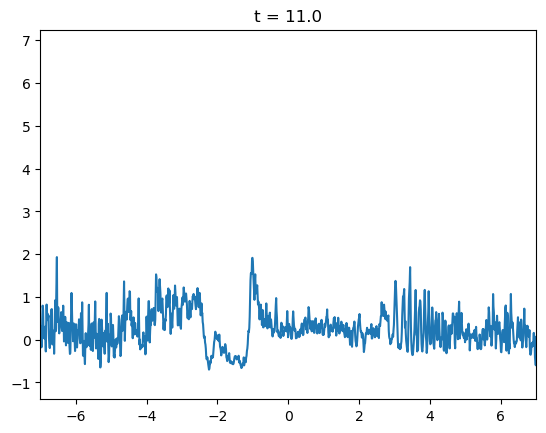

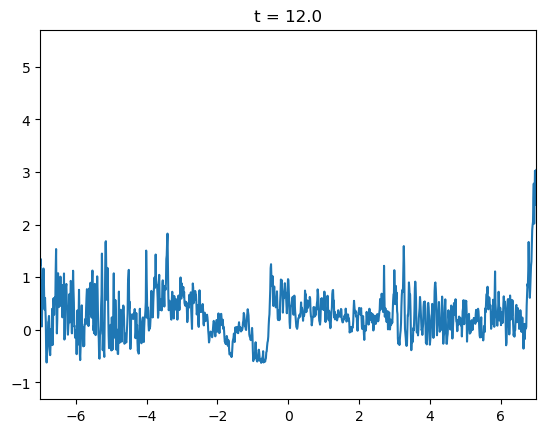

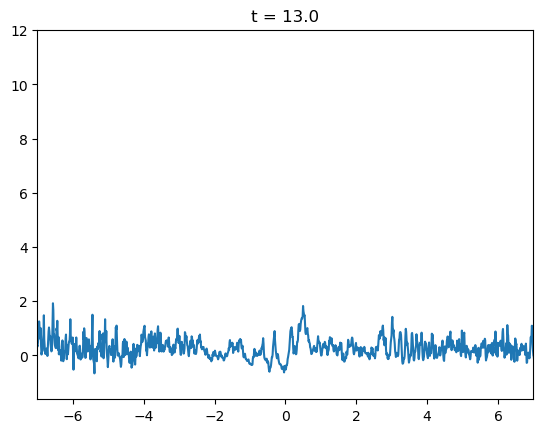

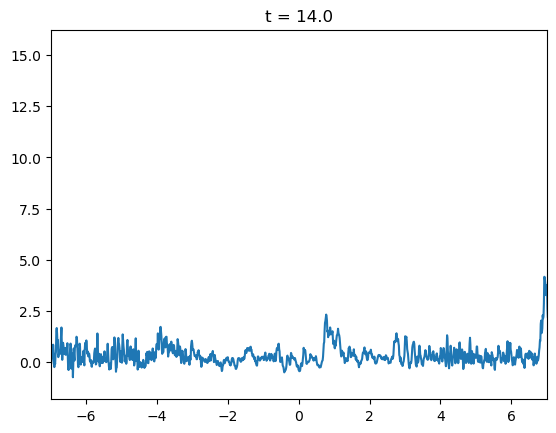

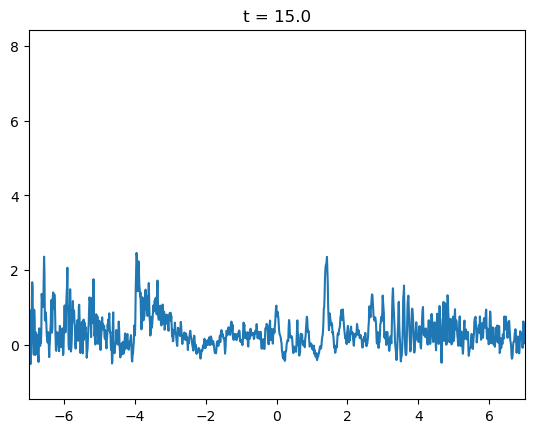

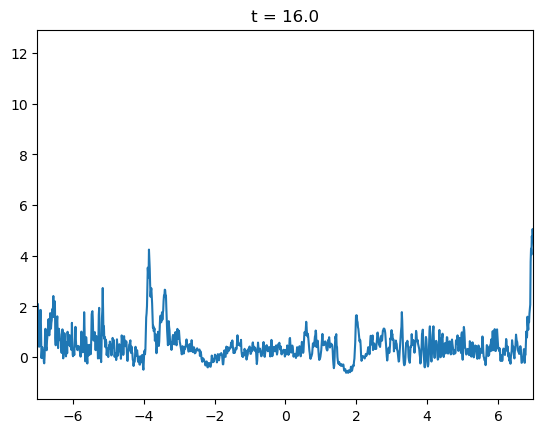

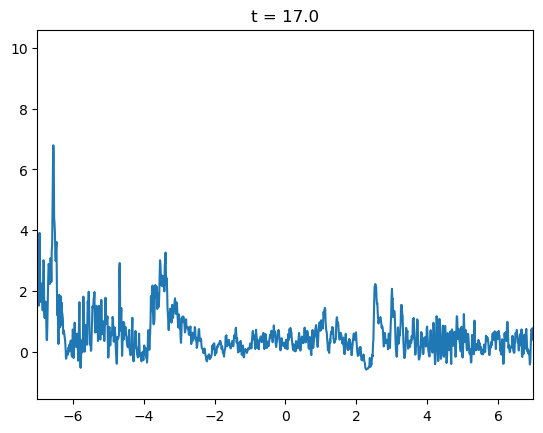

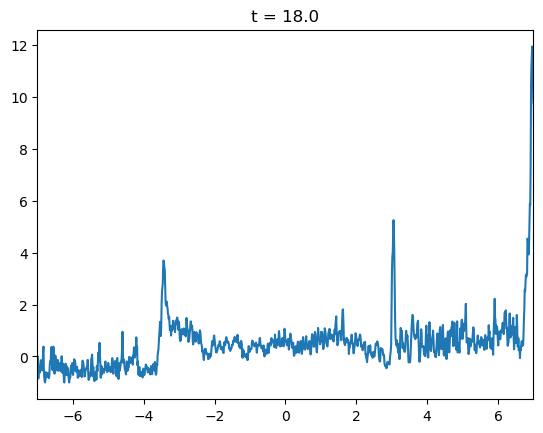

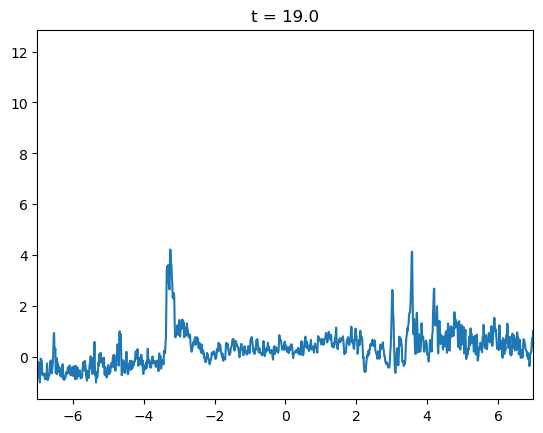

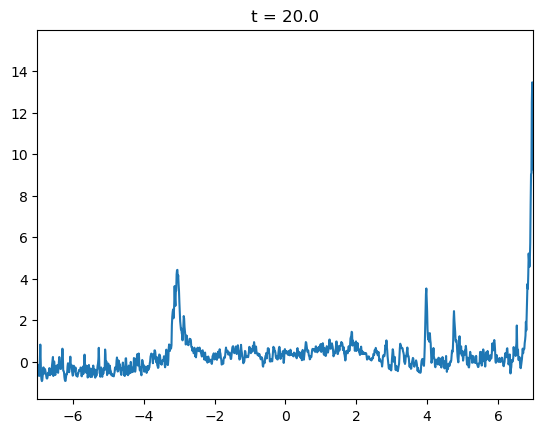

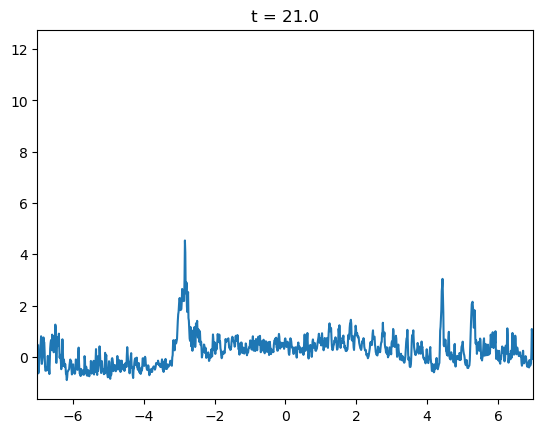

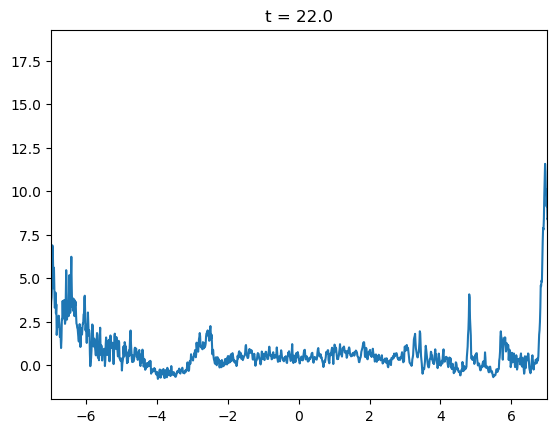

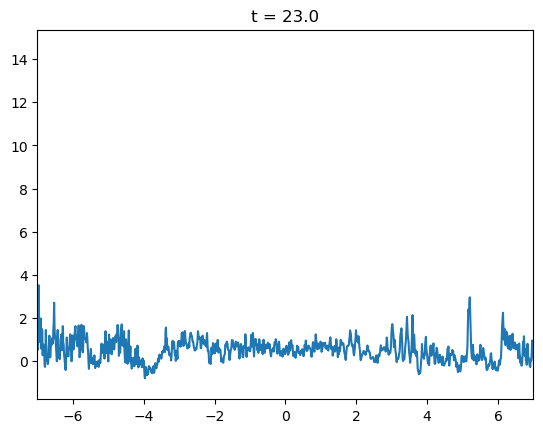

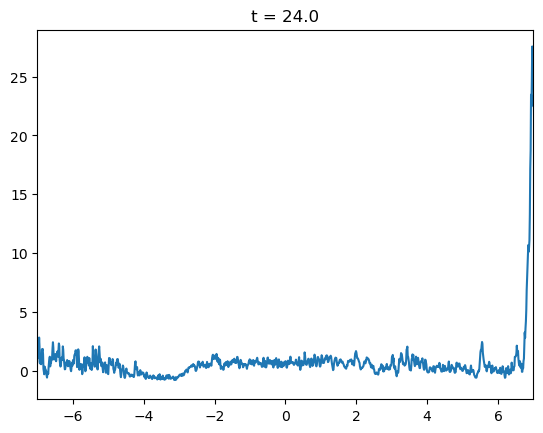

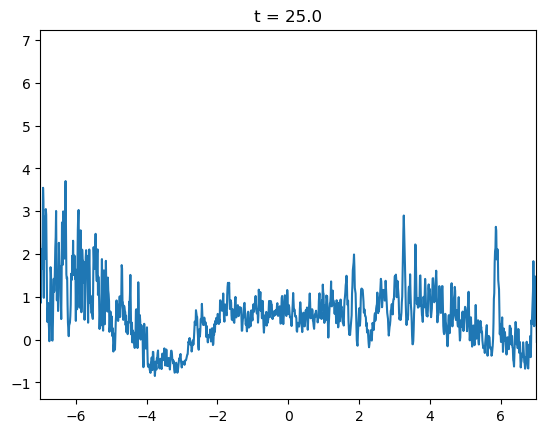

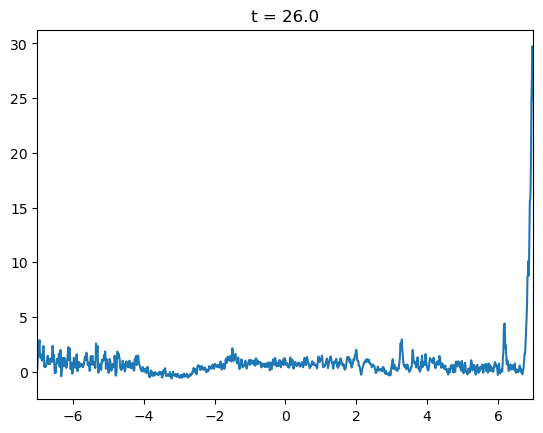

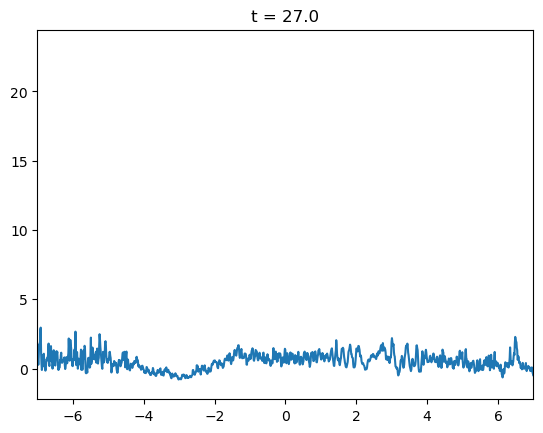

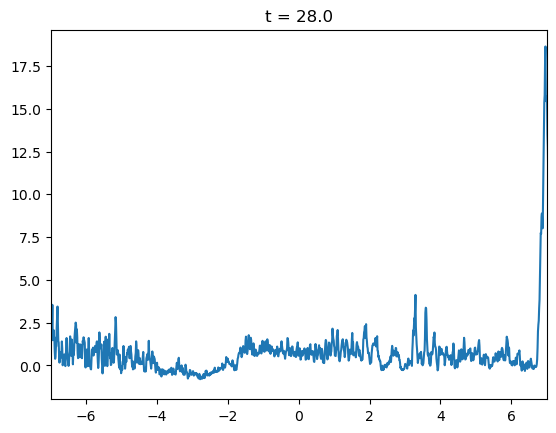

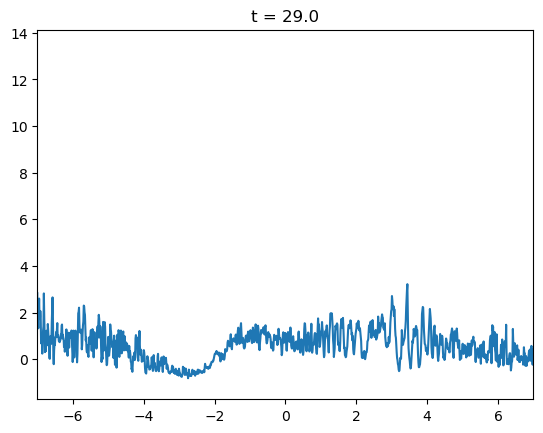

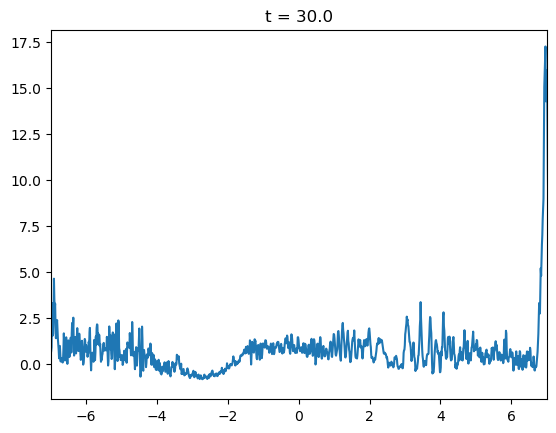

<Figure size 640x480 with 0 Axes>

In [8]:
for i in range(len(times_shock)):
    plt.plot(pos_shock[i], lineouts_shock[i])
    plt.title(f't = {times_shock[i]}')
    plt.xlim(-7,7)
    plt.show()
    plt.clf()

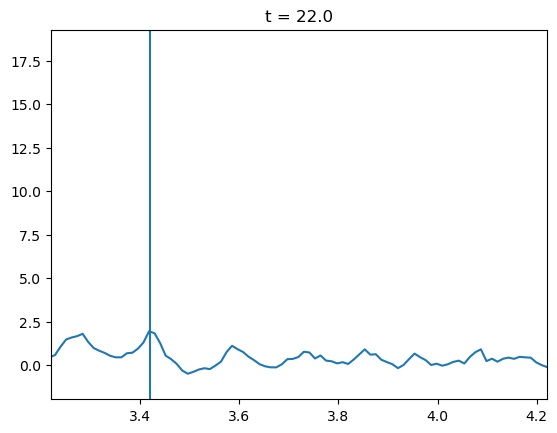

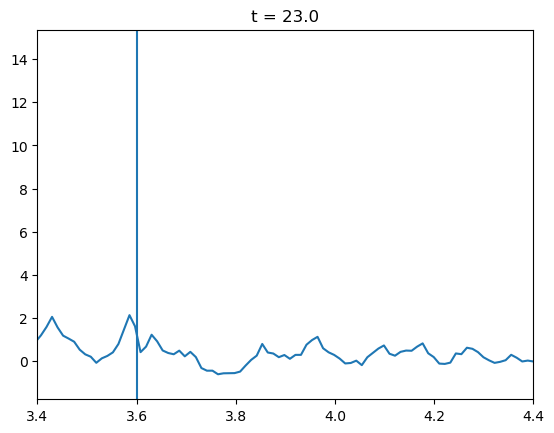

<Figure size 640x480 with 0 Axes>

In [9]:
i = 12
plt.plot(pos_shock[i], lineouts_shock[i])
plt.axvline(3.42)

plt.title(f't = {times_shock[i]}')
plt.xlim(3.22,4.22)
plt.show()
plt.clf()

i = 13
plt.plot(pos_shock[i], lineouts_shock[i])
plt.axvline(3.6)

plt.title(f't = {times_shock[i]}')
plt.xlim(3.4,4.4)
plt.show()
plt.clf()

In [10]:
# average lineouts over 2 ns 
x_common = np.linspace(-2, 2, 1000)

times_avg_1516 = np.linspace(15, 16, 51)
pos_avg_1516, lineouts_avg_1516 = afn.get_lineouts(streak, times_avg_1516, background, calib_factors, ext)

times_avg_1617 = np.linspace(16, 17, 51)
pos_avg_1617, lineouts_avg_1617 = afn.get_lineouts(streak, times_avg_1617, background, calib_factors, ext)

times_avg_1718 = np.linspace(17, 18, 51)
pos_avg_1718, lineouts_avg_1718 = afn.get_lineouts(streak, times_avg_1718, background, calib_factors, ext)

times_avg_1819 = np.linspace(18, 19, 51)
pos_avg_1819, lineouts_avg_1819 = afn.get_lineouts(streak, times_avg_1819, background, calib_factors, ext)

times_avg_1920 = np.linspace(19, 20, 51)
pos_avg_1920, lineouts_avg_1920 = afn.get_lineouts(streak, times_avg_1920, background, calib_factors, ext)

times_avg_2021 = np.linspace(20, 21, 51)
pos_avg_2021, lineouts_avg_2021 = afn.get_lineouts(streak, times_avg_2021, background, calib_factors, ext)

times_avg_2122 = np.linspace(21, 22, 51)
pos_avg_2122, lineouts_avg_2122 = afn.get_lineouts(streak, times_avg_2122, background, calib_factors, ext)

times_avg_2223 = np.linspace(22, 23, 51)
pos_avg_2223, lineouts_avg_2223 = afn.get_lineouts(streak, times_avg_2223, background, calib_factors, ext)

times_avg_2324 = np.linspace(23, 24, 51)
pos_avg_2324, lineouts_avg_2324 = afn.get_lineouts(streak, times_avg_2324, background, calib_factors, ext)

times_avg_2425 = np.linspace(24, 25, 51)
pos_avg_2425, lineouts_avg_2425 = afn.get_lineouts(streak, times_avg_2425, background, calib_factors, ext)

background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...


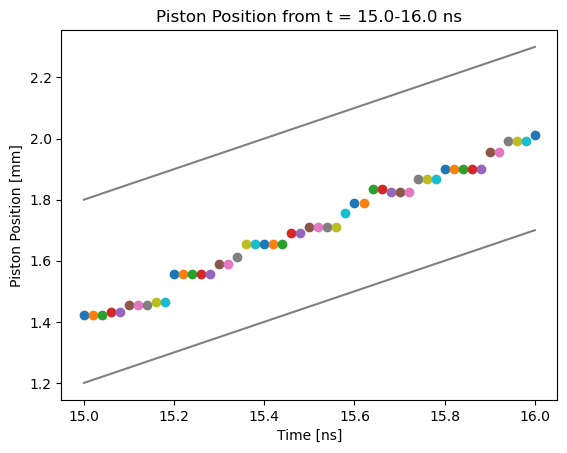

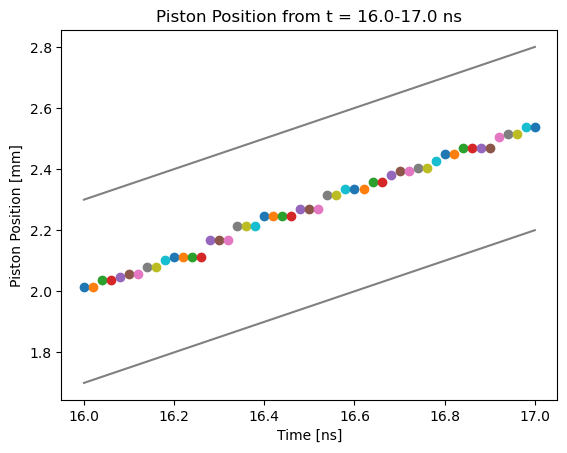

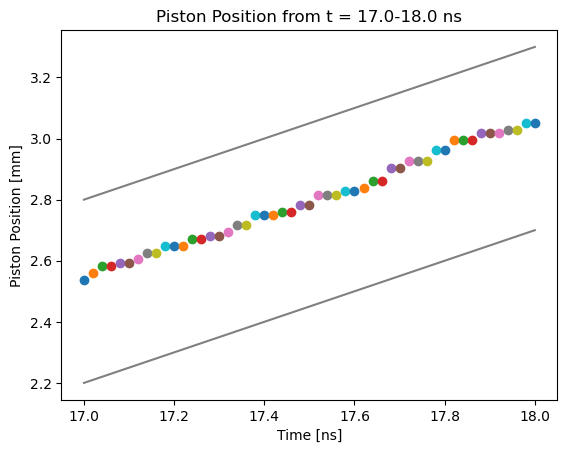

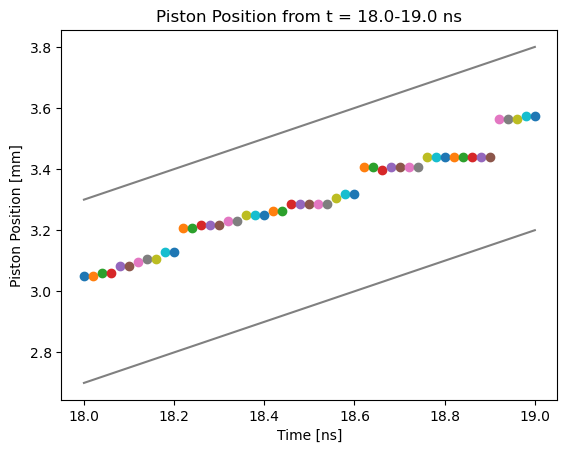

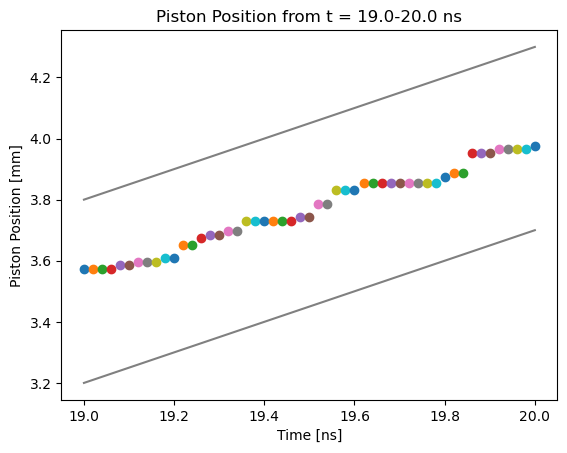

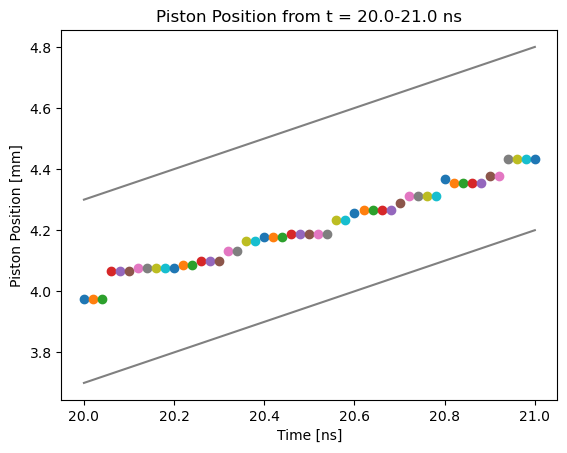

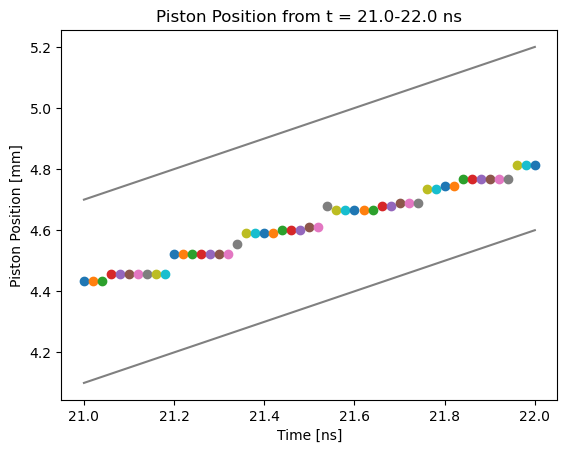

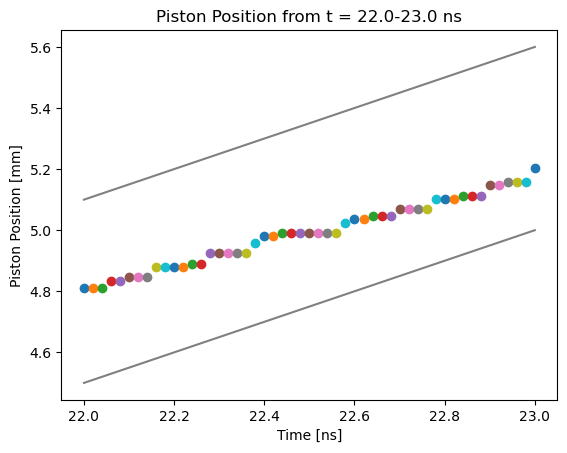

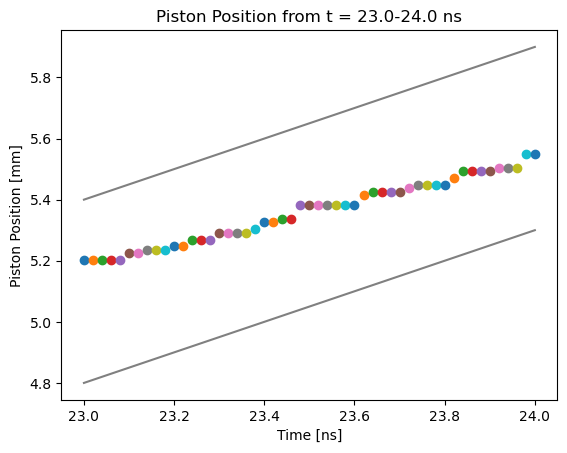

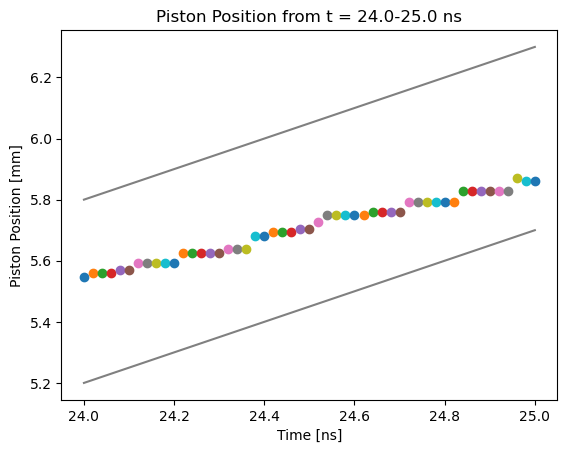

(None, None, None)

In [11]:
times_piston = []
pos_piston = []
lo_piston = []

initial_piston = 1.5
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1516, pos_avg_1516, lineouts_avg_1516, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1516))

initial_piston = 2
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1617, pos_avg_1617, lineouts_avg_1617, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1617))

initial_piston = 2.5
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1718, pos_avg_1718, lineouts_avg_1718, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1718))

initial_piston = 3
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1819, pos_avg_1819, lineouts_avg_1819, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1819))

initial_piston = 3.5
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1920, pos_avg_1920, lineouts_avg_1920, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1920))

initial_piston = 4
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2021, pos_avg_2021, lineouts_avg_2021, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2021))

initial_piston = 4.4
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2122, pos_avg_2122, lineouts_avg_2122, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2122))

initial_piston = 4.8
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2223, pos_avg_2223, lineouts_avg_2223, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2223))

initial_piston = 5.1
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2324, pos_avg_2324, lineouts_avg_2324, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2324))

initial_piston = 5.5
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2425, pos_avg_2425, lineouts_avg_2425, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2425))

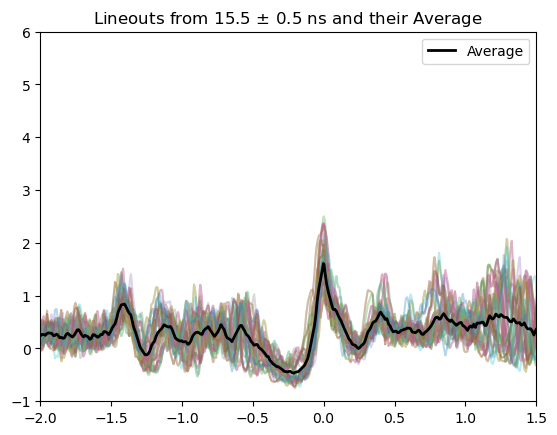

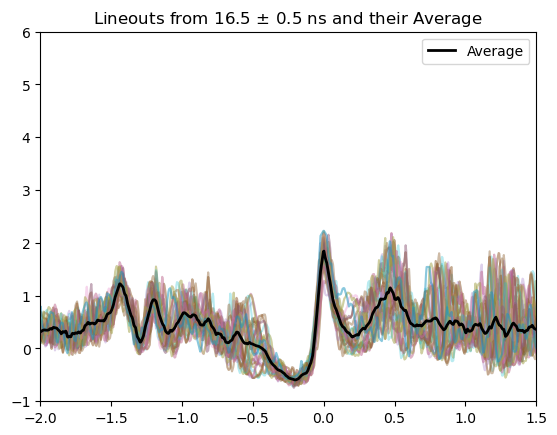

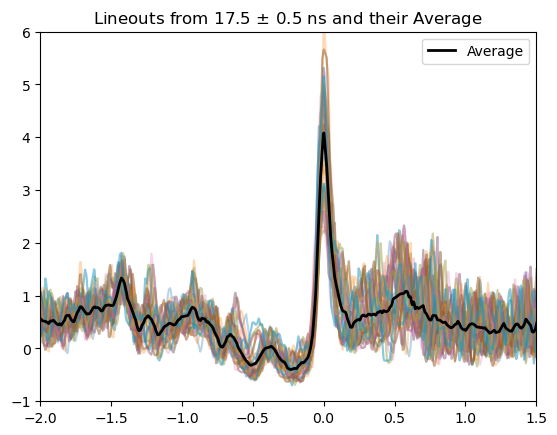

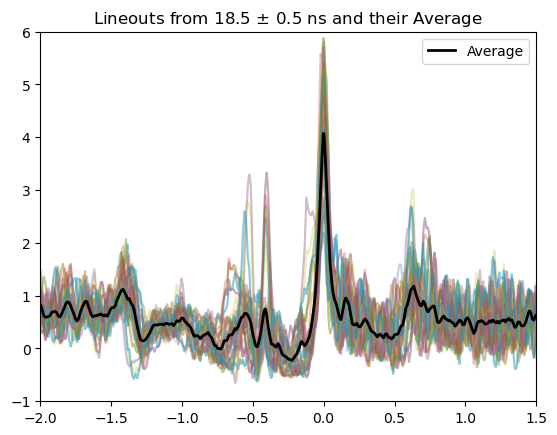

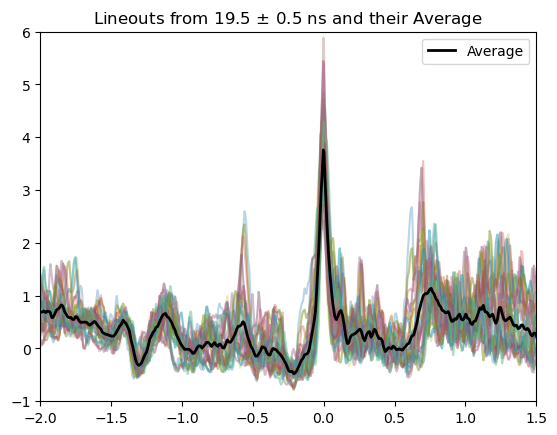

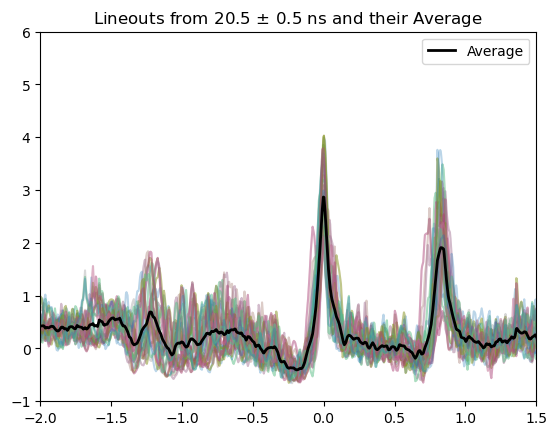

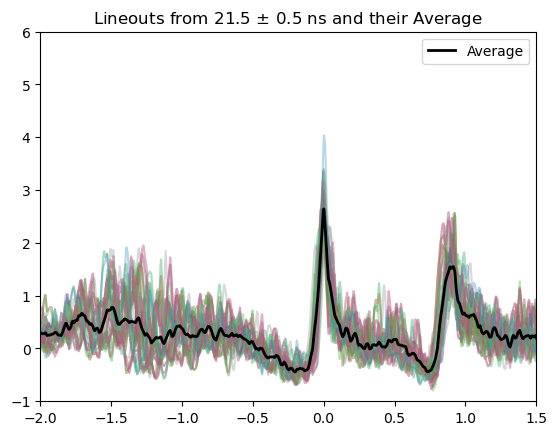

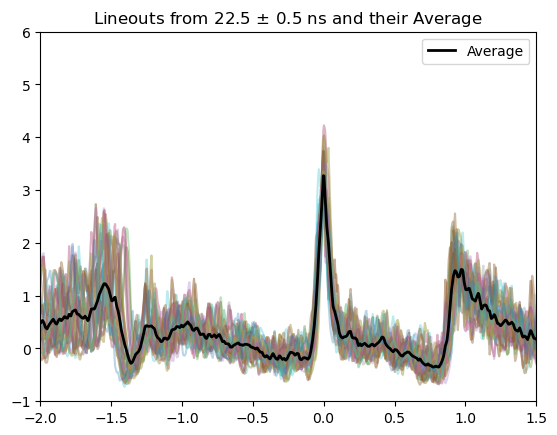

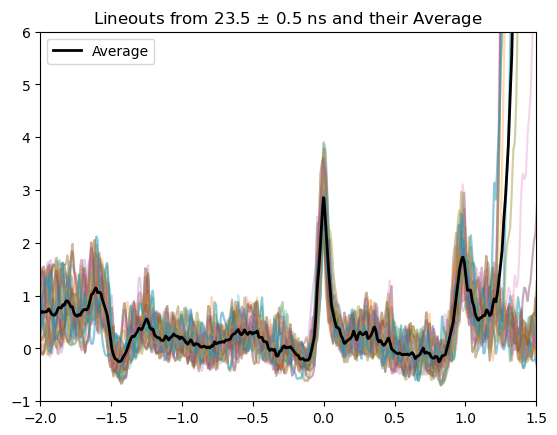

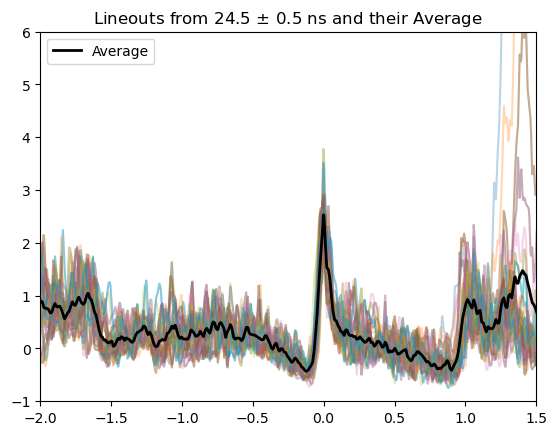

In [12]:
averages_piston = []
for i in range(len(times_piston)):
    n_lines = len(lo_piston[i])
    for j in range(n_lines):
        plt.plot(x_common, lo_piston[i][j], alpha=0.3)
    
    average_lo = np.mean(lo_piston[i][:n_lines], axis=0)
    x = x_common
    
    if times_piston[i] > 23:
        mask = x_common < 2
        average_lo = average_lo[mask]
        x = x_common[mask]
        x_cut = x
    averages_piston.append(average_lo)
    
    plt.plot(x, average_lo, color='black', linewidth=2, label='Average')
    plt.xlim(-2,1.5)
    plt.ylim(-1,6)
    plt.title(f'Lineouts from {times_piston[i]} $\pm$ 0.5 ns and their Average')
    plt.legend()
    plt.show()

In [13]:
# save intensity to PRAD input 
for i in range(len(averages_piston)):
    I_array = 1 + averages_piston[i]
    I0_array = 1.0
    
    savemat(f'../proton_radiography/prad_inputs/bg1_data_{times_piston[i]}.mat', {
        'X0': x_common,        # Spatial coordinate array
        'I':  I_array,        # Intensity with plasma
        'I0': I0_array        # Background intensity
    })

# Model Shocks

In [14]:
x_array = []
y_raw_array = []
y_fit_array = []
dndx_0_array = []
dndx_ns_array = []
dndx_array = []
ne_0_array = []
ne_array = []
ne_ns_array = []

diag_mins = []
diag_maxs = []
diag_times = []

shift: 0.235
diag min: -1.2512512512512513 diag max: -1.4074074074074074


(None, None, None)

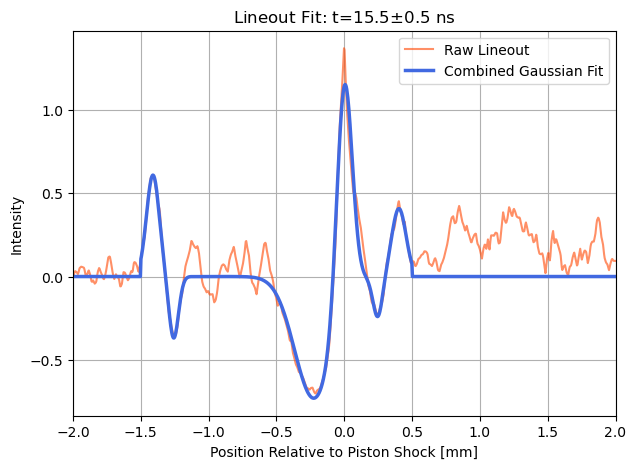

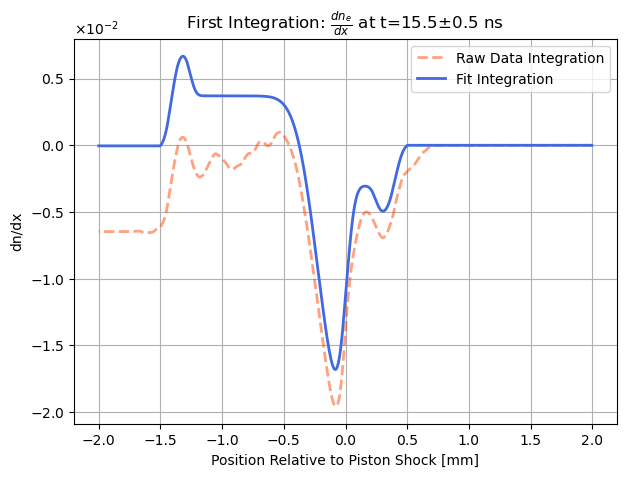

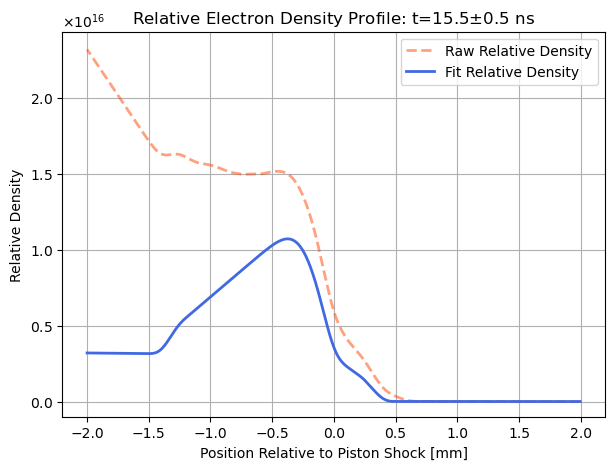

In [15]:
idx = 0
shift = 0.235
print('shift:', shift)

y_rawraw = averages_piston[idx]
y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]
y_noshift = y_rawraw[sort_descending]

piston_lim = [-0.8, 0.4]
mag_lim = [0.1, 0.5]
diag_lim = [-1.5, -1.1]

diag_min, diag_max = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])
diag_mins.append(diag_min), diag_maxs.append(diag_max), diag_times.append(times_piston[idx])

# x, y_fit, dndx0, dndx, dndx0ns, ne0, ne, ne0ns = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])

# x_array.append(x), y_raw_array.append(y_raw), y_fit_array.append(y_fit), dndx_0_array.append(dndx0), dndx_array.append(dndx)
# dndx_ns_array.append(ne0ns), ne_0_array.append(ne0), ne_array.append(ne), ne_ns_array.append(ne0ns)

shift: 0.375
diag min: -1.2952952952952952 diag max: -1.4394394394394394


(None, None, None)

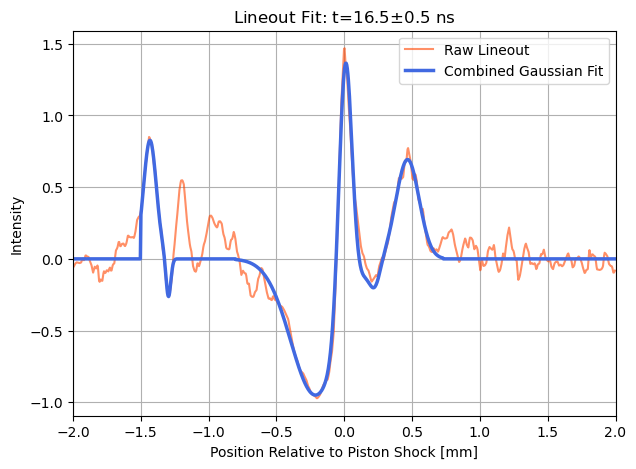

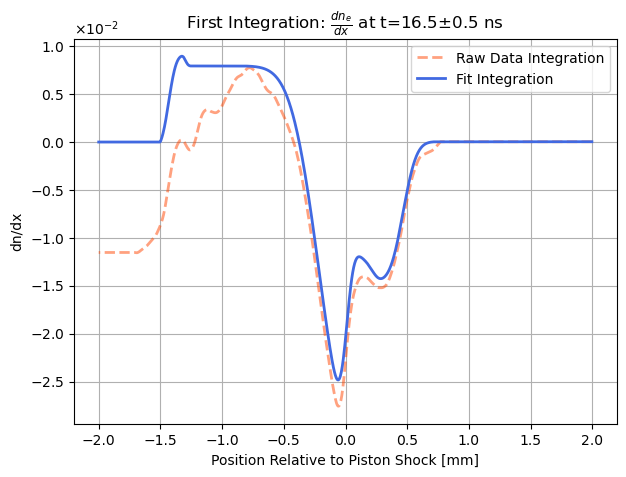

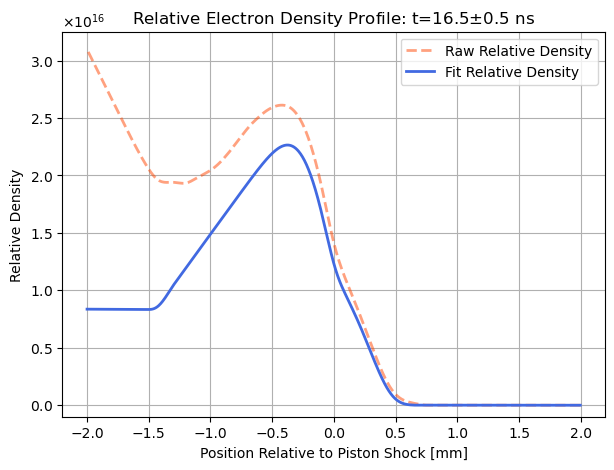

In [16]:
idx = 1
shift = 0.375
print('shift:', shift)

y_rawraw = averages_piston[idx]
y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]
y_noshift = y_rawraw[sort_descending]

piston_lim = [-0.8, 0.4]
mag_lim = [0.1, 0.73]
diag_lim = [-1.5, -1.1]

diag_min, diag_max = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])
diag_mins.append(diag_min), diag_maxs.append(diag_max), diag_times.append(times_piston[idx])

# x, y_fit, dndx0, dndx, dndx0ns, ne0, ne, ne0ns = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])

# x_array.append(x), y_raw_array.append(y_raw), y_fit_array.append(y_fit), dndx_0_array.append(dndx0), dndx_array.append(dndx)
# dndx_ns_array.append(ne0ns), ne_0_array.append(ne0), ne_array.append(ne), ne_ns_array.append(ne0ns)

shift: 0.555
diag min: -1.3033033033033035 diag max: -1.4274274274274275


(None, None, None)

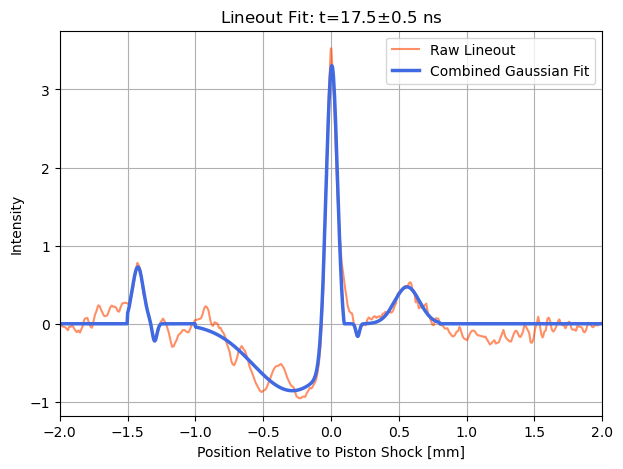

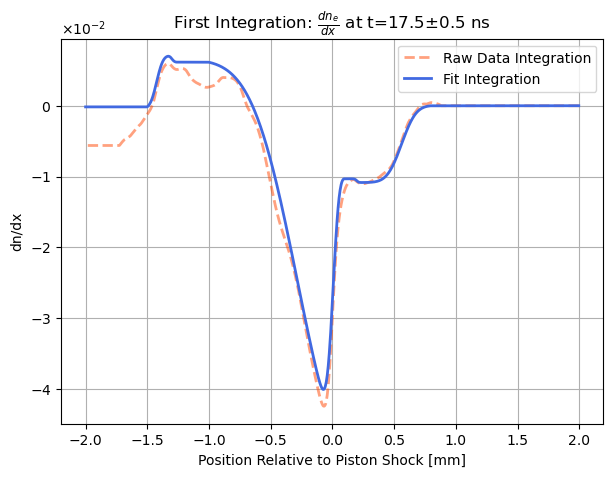

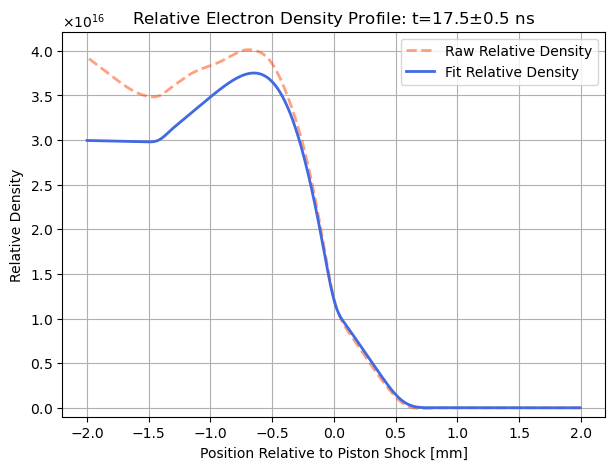

In [17]:
idx = 2
shift = 0.555
print('shift:', shift)

y_rawraw = averages_piston[idx]
y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]
y_noshift = y_rawraw[sort_descending]

piston_lim = [-1, 0.095]
mag_lim = [0.1, 0.8]
diag_lim = [-1.5, -1.2]

diag_min, diag_max = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])
diag_mins.append(diag_min), diag_maxs.append(diag_max), diag_times.append(times_piston[idx])

# x, y_fit, dndx0, dndx, dndx0ns, ne0, ne, ne0ns = afn.plot_shock_density(x_data, y_data, y_noshift, piston_lim, mag_lim, times_piston[idx])

# x_array.append(x), y_raw_array.append(y_raw), y_fit_array.append(y_fit), dndx_0_array.append(dndx0), dndx_array.append(dndx)
# dndx_ns_array.append(ne0ns), ne_0_array.append(ne0), ne_array.append(ne), ne_ns_array.append(ne0ns)

shift: 0.627
diag min: -1.2712712712712713 diag max: -1.4154154154154153


(None, None, None)

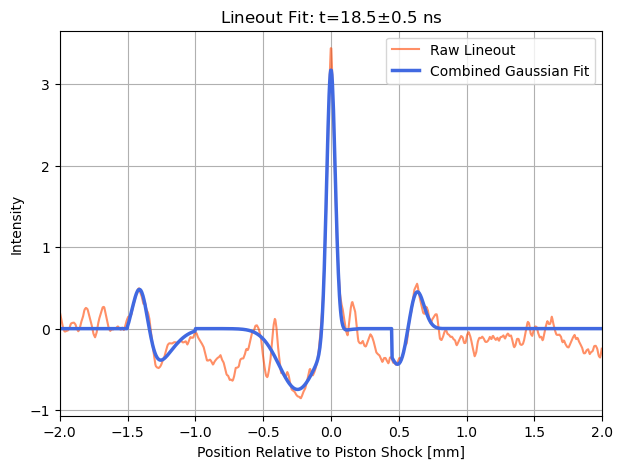

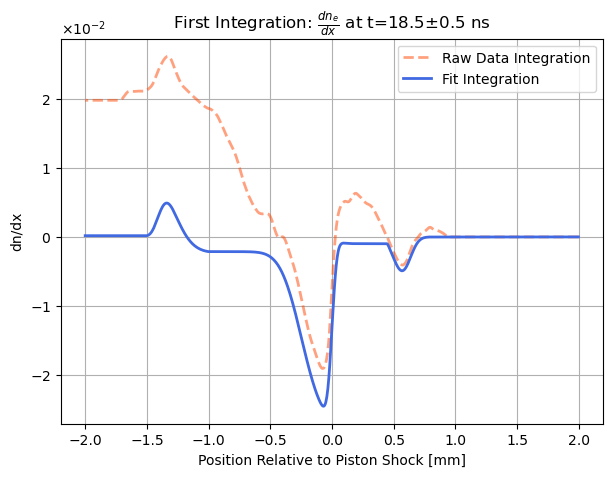

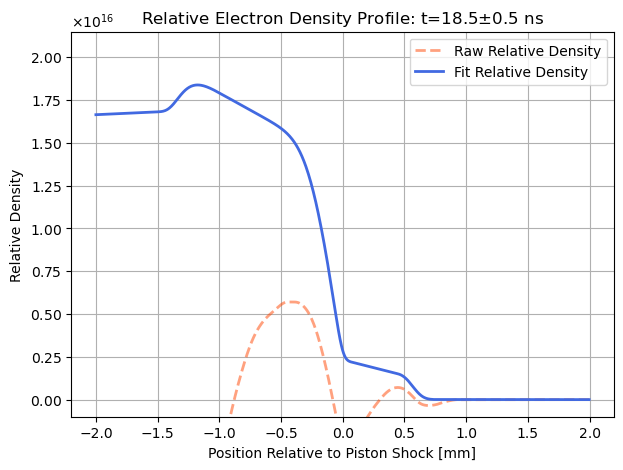

In [18]:
idx = 3
# shift = 0.596
shift = 0.627
print('shift:', shift)

y_rawraw = averages_piston[idx]
y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]
y_noshift = y_rawraw[sort_descending]

piston_lim = [-0.8, 0.2]
mag_lim = [0.45, 1]
diag_lim = [-1.5, -1]

diag_min, diag_max = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])
diag_mins.append(diag_min), diag_maxs.append(diag_max), diag_times.append(times_piston[idx])

# x, y_fit, dndx0, dndx, dndx0ns, ne0, ne, ne0ns = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])

# x_array.append(x), y_raw_array.append(y_raw), y_fit_array.append(y_fit), dndx_0_array.append(dndx0), dndx_array.append(dndx)
# dndx_ns_array.append(ne0ns), ne_0_array.append(ne0), ne_array.append(ne), ne_ns_array.append(ne0ns)

shift: 0.35
diag min: -1.3033033033033035 diag max: -1.4154154154154153


(None, None, None)

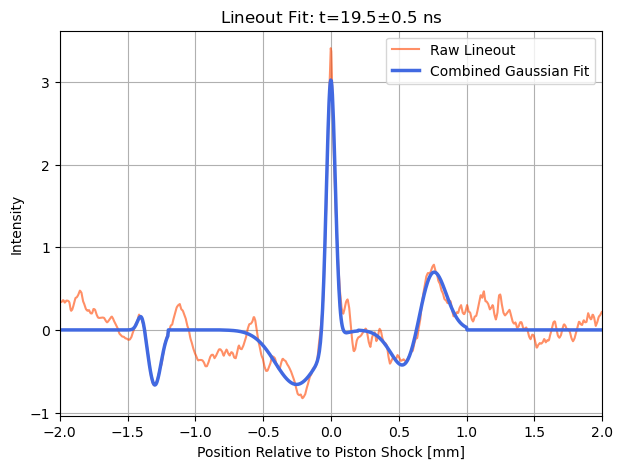

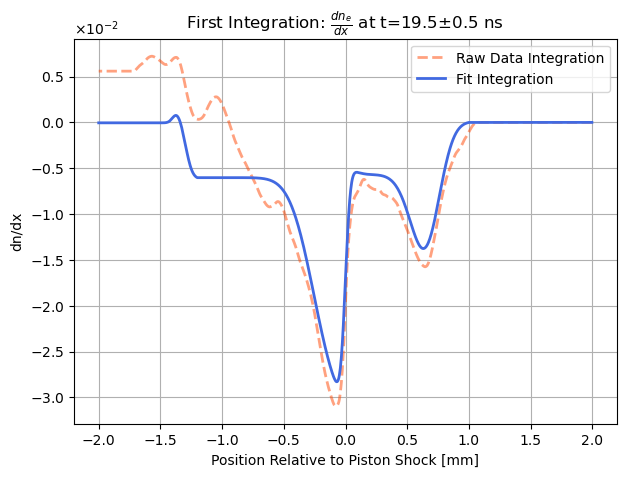

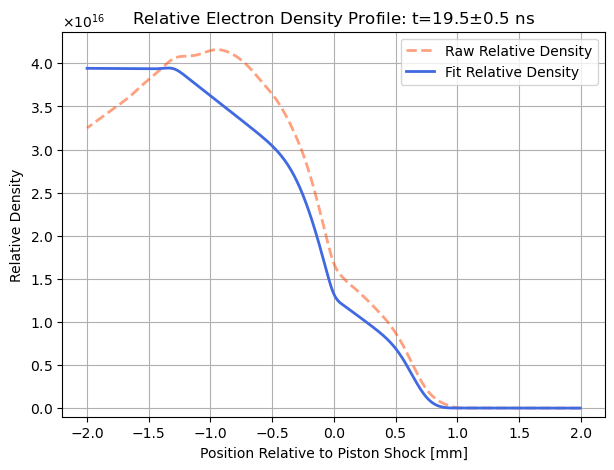

In [19]:
idx = 4
shift = 0.35
print('shift:', shift)

y_rawraw = averages_piston[idx]
y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]
y_noshift = y_rawraw[sort_descending]

piston_lim = [-0.8, 0.2]
mag_lim = [0.1, 1]
diag_lim = [-1.5, -1.2]

diag_min, diag_max = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])
diag_mins.append(diag_min), diag_maxs.append(diag_max), diag_times.append(times_piston[idx])

# x, y_fit, dndx0, dndx, dndx0ns, ne0, ne, ne0ns = afn.plot_shock_density(x_data, y_data, y_noshift, piston_lim, mag_lim, times_piston[idx])

# x_array.append(x), y_raw_array.append(y_raw), y_fit_array.append(y_fit), dndx_0_array.append(dndx0), dndx_array.append(dndx)
# dndx_ns_array.append(ne0ns), ne_0_array.append(ne0), ne_array.append(ne), ne_ns_array.append(ne0ns)

shift: 0.297
diag min: -1.0710710710710711 diag max: -1.2232232232232232


(None, None, None)

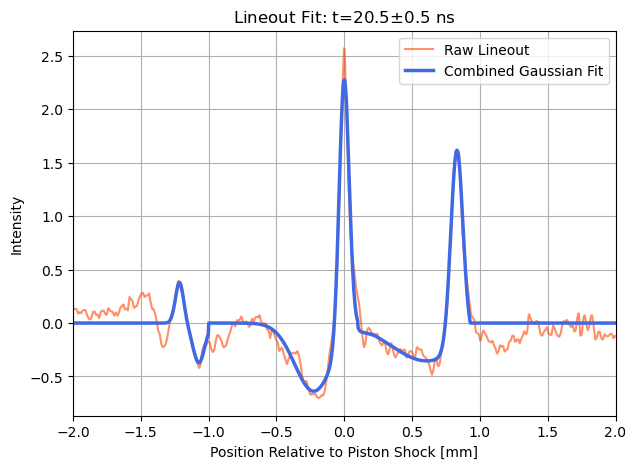

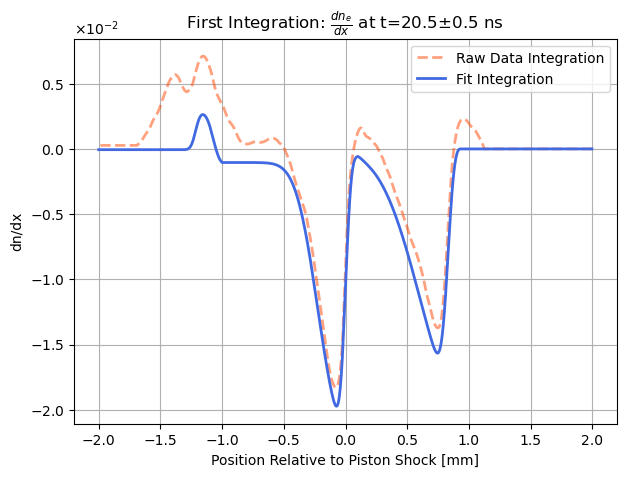

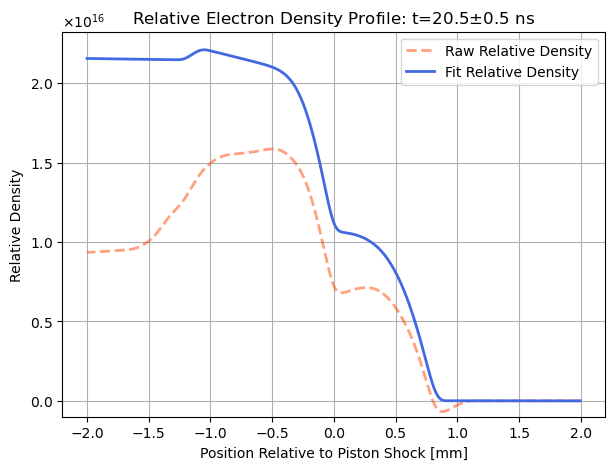

In [20]:
idx = 5 

shift = 0.297
print('shift:', shift)

y_rawraw = averages_piston[idx]
y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]
y_noshift = y_rawraw[sort_descending]

piston_lim = [-0.8, 0.2]
mag_lim = [0.1, 0.93]
diag_lim = [-1.5, -1]

diag_min, diag_max = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])
diag_mins.append(diag_min), diag_maxs.append(diag_max), diag_times.append(times_piston[idx])

# x, y_fit, dndx0, dndx, dndx0ns, ne0, ne, ne0ns = afn.plot_shock_density(x_data, y_data, y_noshift, piston_lim, mag_lim, times_piston[idx])

# x_array.append(x), y_raw_array.append(y_raw), y_fit_array.append(y_fit), dndx_0_array.append(dndx0), dndx_array.append(dndx)
# dndx_ns_array.append(ne0ns), ne_0_array.append(ne0), ne_array.append(ne), ne_ns_array.append(ne0ns)

shift: 0.255
diag min: -1.1271271271271273 diag max: -1.3073073073073074


(None, None, None)

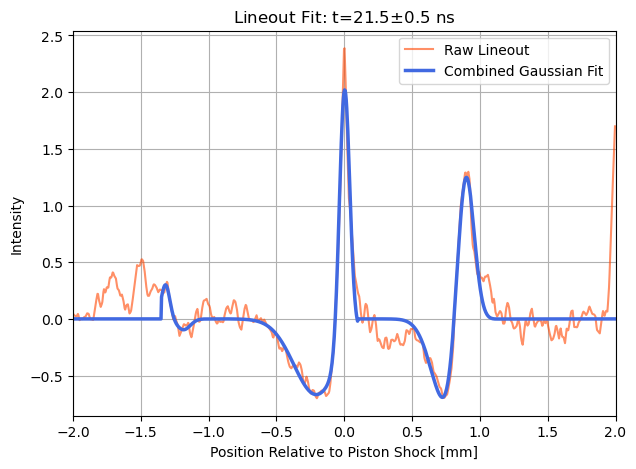

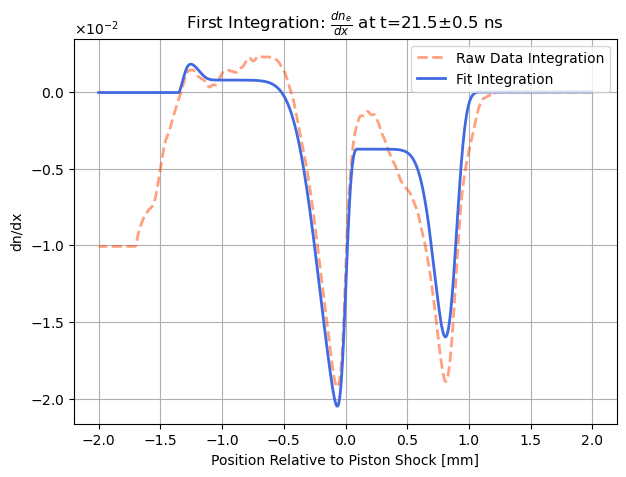

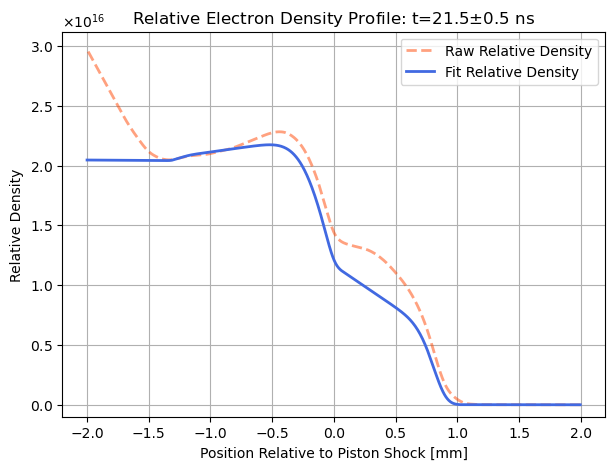

In [21]:
idx = 6

shift = 0.255
print('shift:', shift)

y_rawraw = averages_piston[idx]
y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]
y_noshift = y_rawraw[sort_descending]

piston_lim = [-0.8, 0.1]
mag_lim = [0.1, 1.2]
diag_lim = [-1.35, -1]

diag_min, diag_max = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])
diag_mins.append(diag_min), diag_maxs.append(diag_max), diag_times.append(times_piston[idx])

# x, y_fit, dndx0, dndx, dndx0ns, ne0, ne, ne0ns = afn.plot_shock_density(x_data, y_data, y_noshift, piston_lim, mag_lim, times_piston[idx])

# x_array.append(x), y_raw_array.append(y_raw), y_fit_array.append(y_fit), dndx_0_array.append(dndx0), dndx_array.append(dndx)
# dndx_ns_array.append(ne0ns), ne_0_array.append(ne0), ne_array.append(ne), ne_ns_array.append(ne0ns)

shift: 0.335
diag min: -1.3593593593593594 diag max: -1.5475475475475475


(None, None, None)

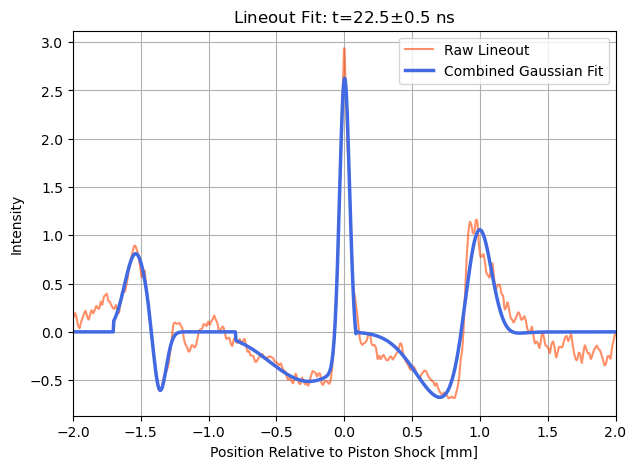

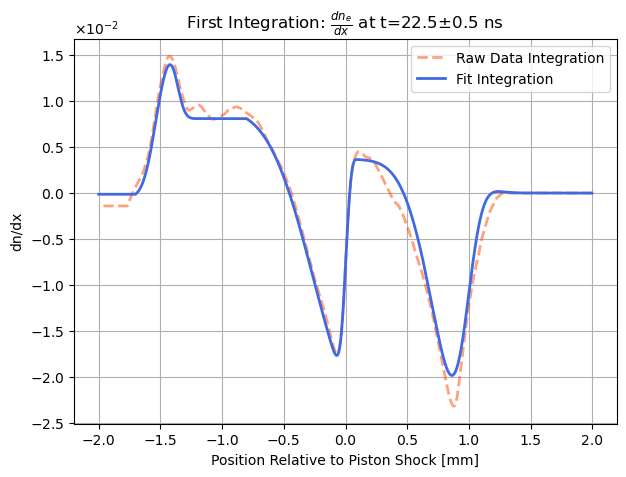

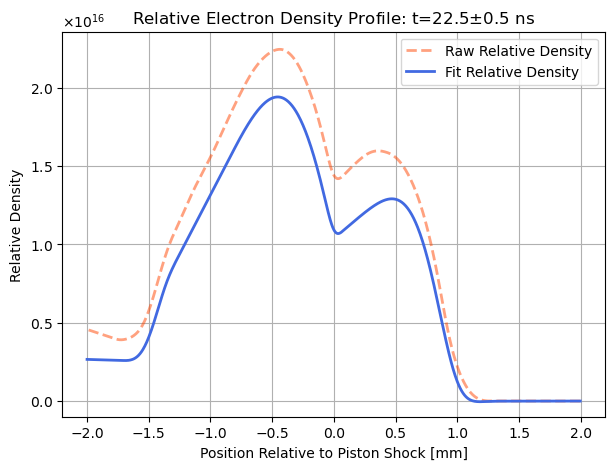

In [22]:
idx = 7

shift = 0.335
print('shift:', shift)

y_rawraw = averages_piston[idx]
y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]
y_noshift = y_rawraw[sort_descending]

piston_lim = [-0.8, 0.09]
mag_lim = [0.1, 1.5]
diag_lim = [-1.7, -1.2]

diag_min, diag_max = afn.plot_shock_density_3rd(x_data, y_data, y_noshift, piston_lim, mag_lim, diag_lim, times_piston[idx])
diag_mins.append(diag_min), diag_maxs.append(diag_max), diag_times.append(times_piston[idx])

# x, y_fit, dndx0, dndx, dndx0ns, ne0, ne, ne0ns = afn.plot_shock_density(x_data, y_data, y_noshift, piston_lim, mag_lim, times_piston[idx])

# x_array.append(x), y_raw_array.append(y_raw), y_fit_array.append(y_fit), dndx_0_array.append(dndx0), dndx_array.append(dndx)
# dndx_ns_array.append(ne0ns), ne_0_array.append(ne0), ne_array.append(ne), ne_ns_array.append(ne0ns)

In [23]:
filename = "../proton_radiography/analysis_outputs/fit.h5"

with h5py.File(filename, "w") as f:
    for i in range(len(x_array)):
        grp = f.create_group(f"{times_piston[i]}")
        
        # Save arrays inside the set's group
        grp.create_dataset("x", data=x_array[i])
        grp.create_dataset("y_raw", data=y_raw_array[i])
        grp.create_dataset("y_fit", data=y_fit_array[i])
        grp.create_dataset("dndx_raw", data=dndx_0_array[i])
        grp.create_dataset("dndx_adj", data=dndx_array[i])
        grp.create_dataset("ne_raw", data=ne_0_array[i])
        grp.create_dataset("ne_adj", data=ne_array[i])

print(f"Successfully saved {len(x_array)} sets to {filename} (should be 10)")

Successfully saved 0 sets to ../proton_radiography/analysis_outputs/fit.h5 (should be 10)


In [24]:
all_peaks = []
peak_times = []

# t = 15
i = 5
piston_lims = [0.5, 2]
mag_lims = [1.5, 2]
diag_lims = [(2-1.5), (2-1.2)]
# peaks_15 = afn.find_shock_positions_3rd(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims, diag_lims)
peaks_15 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_15)
peak_times.append(times_shock[i])

# t = 16
i = 6
piston_lims = [1, 3]
mag_lims = [2.3, 2.55]
diag_lims = [(2-1.5), (2-1.2)]
peaks_16 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_16)
peak_times.append(times_shock[i])

i = 7
piston_lims = [1, 4]
mag_lims = [2.8, 3.05]
peaks_17 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_17)
peak_times.append(times_shock[i])

i = 8
piston_lims = [1, 4]
mag_lims = [3.4, 4]
peaks_18 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_18)
peak_times.append(times_shock[i])

i = 9
piston_lims = [3.2, 4]
mag_lims = [3.7, 4.5]
peaks_19 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_19)
peak_times.append(times_shock[i])

i = 10
piston_lims = [3.2, 4]
mag_lims = [4.5, 5]
peaks_20 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_20)
peak_times.append(times_shock[i])

i = 11
piston_lims = [4, 5]
mag_lims = [5, 6]
peaks_21 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_21)
peak_times.append(times_shock[i])

i = 12
piston_lims = [4, 5]
mag_lims = [5, 6]
peaks_22 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_22)
peak_times.append(times_shock[i])

i = 13
piston_lims = [4.5, 5.5]
mag_lims = [5.5, 6.5]
peaks_23 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_23)
peak_times.append(times_shock[i])

i = 14
piston_lims = [4.5, 5.5]
mag_lims = [6, 6.7]
peaks_24 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_24)
peak_times.append(times_shock[i])

i = 15
piston_lims = [5, 6]
mag_lims = [6, 7]
peaks_25 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_25)
peak_times.append(times_shock[i])

i = 17
piston_lims = [6.4, 6.5]
mag_lims = [7.4, 8]
peaks_26 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_26)
peak_times.append(times_shock[i])

all_peaks = np.array(all_peaks)

<Figure size 640x480 with 0 Axes>

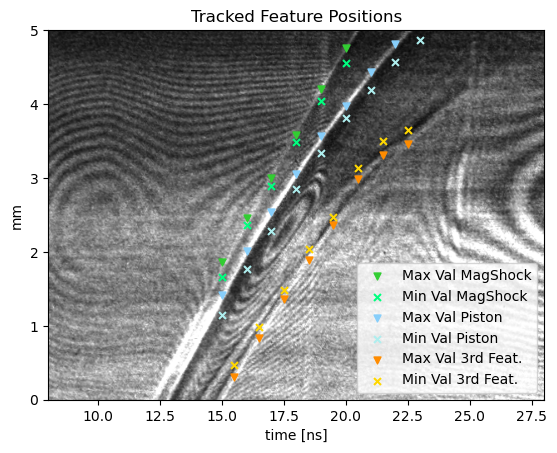

In [32]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.scatter(peak_times, all_peaks[:,3], color = 'limegreen', s = 25, label = 'Max Val MagShock', marker = 'v')
plt.scatter(peak_times, all_peaks[:,2], color = 'springgreen', s = 25, label = 'Min Val MagShock', marker = 'x')
plt.scatter(peak_times, all_peaks[:,1], color = 'lightskyblue', s = 25, label = 'Max Val Piston', marker = 'v')
plt.scatter(peak_times, all_peaks[:,0], color = 'paleturquoise', s = 25, label = 'Min Val Piston', marker = 'x')
# plt.scatter(peak_times, all_peaks[:,4], color = 'darkorange', s = 25, label = 'Max Val 3rd Feat', marker = 'v')
# plt.scatter(peak_times, all_peaks[:,5], color = 'gold', s = 25, label = 'Min Val 3rd Feat', marker = 'x')


plt.scatter(diag_times[0], (all_peaks[0,1] + all_peaks[0+1,1])/2 + diag_maxs[0], color = 'darkorange', s = 25, label = 'Max Val 3rd Feat.', marker = 'v')
plt.scatter(diag_times[0], (all_peaks[0,1] + all_peaks[0+1,1])/2 + diag_mins[0], color = 'gold', s = 25, label = 'Min Val 3rd Feat.', marker = 'x')

for j in range(len(diag_times) - 1):
    i = j + 1
    plt.scatter(diag_times[i], (all_peaks[i,1] + all_peaks[i+1,1])/2 + diag_maxs[i], color = 'darkorange', s = 25, marker = 'v')
    plt.scatter(diag_times[i], (all_peaks[i,1] + all_peaks[i+1,1])/2 + diag_mins[i], color = 'gold', s = 25, marker = 'x')

# plt.axvline(21, color = 'tab:red', label = 'Lineout')

# print('min diag:', all_peaks[:,5])
# print('max diag:', all_peaks[:,4])

plt.xlim(8, 28)
plt.ylim(0, 8)
plt.ylim(0, 5)
plt.legend(loc = 'lower right')
plt.title('Tracked Feature Positions')

plt.savefig('streak_images/shock_with_third', bbox_inches = 'tight')